In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
df = pd.read_csv(r"C:\Users\NAGARAJ P\Desktop\G_B\bank.csv")

In [4]:
df.info()
df.describe()
df.columns.to_list()

<class 'pandas.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        11162 non-null  int64
 1   job        11162 non-null  str  
 2   marital    11162 non-null  str  
 3   education  11162 non-null  str  
 4   default    11162 non-null  str  
 5   balance    11162 non-null  int64
 6   housing    11162 non-null  str  
 7   loan       11162 non-null  str  
 8   contact    11162 non-null  str  
 9   day        11162 non-null  int64
 10  month      11162 non-null  str  
 11  duration   11162 non-null  int64
 12  campaign   11162 non-null  int64
 13  pdays      11162 non-null  int64
 14  previous   11162 non-null  int64
 15  poutcome   11162 non-null  str  
 16  deposit    11162 non-null  str  
dtypes: int64(7), str(10)
memory usage: 2.0 MB


['age',
 'job',
 'marital',
 'education',
 'default',
 'balance',
 'housing',
 'loan',
 'contact',
 'day',
 'month',
 'duration',
 'campaign',
 'pdays',
 'previous',
 'poutcome',
 'deposit']

In [6]:
df.isnull().sum()
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


In [8]:
# Target distribution
print("\nTarget distribution:")
print(df["deposit"].value_counts())

# Target distribution in percentages
print("\nTarget percentages:")
print(df["deposit"].value_counts(normalize=True) * 100)

# Duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())


Target distribution:
deposit
no     5873
yes    5289
Name: count, dtype: int64

Target percentages:
deposit
no     52.616019
yes    47.383981
Name: proportion, dtype: float64

Duplicate rows: 0


In [9]:

# Identify categorical and numerical columns

categorical_cols = df.select_dtypes(include="object").columns
numerical_cols = df.select_dtypes(exclude="object").columns

print("Categorical columns:")
print(categorical_cols.tolist())

print("\nNumerical columns:")
print(numerical_cols.tolist())


Categorical columns:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome', 'deposit']

Numerical columns:
['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']


C:\Users\NAGARAJ P\AppData\Local\Temp\ipykernel_22584\1713127127.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include="object").columns


In [11]:

# Separate input features and target

X = df.drop(columns=["deposit", "duration"])
y = df["deposit"]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nInput features:")
print(X.columns.tolist())

print("\nTarget values:")
print(y.unique())


X shape: (11162, 15)
y shape: (11162,)

Input features:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'campaign', 'pdays', 'previous', 'poutcome']

Target values:
<ArrowStringArray>
['yes', 'no']
Length: 2, dtype: str


In [12]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Identify categorical and numerical input columns
categorical_cols = X.select_dtypes(include=["object", "str"]).columns.tolist()
numerical_cols = X.select_dtypes(exclude=["object", "str"]).columns.tolist()

# Create preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
        ("num", "passthrough", numerical_cols)
    ]
)

print("Categorical columns:", categorical_cols)
print("Numerical columns:", numerical_cols)


Categorical columns: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
Numerical columns: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']


In [13]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X_train: (8929, 15)
X_test: (2233, 15)
y_train: (8929,)
y_test: (2233,)


In [14]:

from sklearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingClassifier

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", GradientBoostingClassifier(random_state=42))
])

# Train the model
model.fit(X_train, y_train)

print("Model training completed!")


Model training completed!


In [15]:

# Predict outcomes for unseen test data
y_pred = model.predict(X_test)

print("First 10 actual values:")
print(y_test.head(10).tolist())

print("\nFirst 10 predicted values:")
print(y_pred[:10])


First 10 actual values:
['no', 'yes', 'no', 'no', 'yes', 'no', 'no', 'yes', 'yes', 'yes']

First 10 predicted values:
['no' 'yes' 'yes' 'no' 'no' 'no' 'no' 'no' 'yes' 'no']


In [16]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.7407075682937752

Classification Report:
              precision    recall  f1-score   support

          no       0.71      0.86      0.78      1175
         yes       0.80      0.61      0.69      1058

    accuracy                           0.74      2233
   macro avg       0.75      0.73      0.73      2233
weighted avg       0.75      0.74      0.74      2233


Confusion Matrix:
[[1011  164]
 [ 415  643]]


In [ ]:
# Improving model performance using GridSearchCV

from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, f1_score

# Treat "yes" as the positive class
yes_f1_scorer = make_scorer(f1_score, pos_label="yes")

grid_search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    scoring=yes_f1_scorer,
    cv=5,
    n_jobs=-1,
    verbose=1,
    error_score="raise"
)

grid_search.fit(X_train, y_train)

print("\nBest parameters:")
print(grid_search.best_params_)

print("\nBest cross-validation F1-score:")
print(grid_search.best_score_)


Fitting 5 folds for each of 16 candidates, totalling 80 fits

Best parameters:
{'classifier__learning_rate': 0.1, 'classifier__max_depth': 3, 'classifier__min_samples_leaf': 1, 'classifier__n_estimators': 150}

Best cross-validation F1-score:
0.6872494050884889


In [21]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Get the best pipeline selected by GridSearchCV
best_model = grid_search.best_estimator_

# Predict on unseen test data
y_pred_tuned = best_model.predict(X_test)

print("Test Accuracy:", accuracy_score(y_test, y_pred_tuned))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_tuned))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_tuned))


Test Accuracy: 0.7451858486341245

Classification Report:
              precision    recall  f1-score   support

          no       0.71      0.86      0.78      1175
         yes       0.80      0.62      0.70      1058

    accuracy                           0.75      2233
   macro avg       0.76      0.74      0.74      2233
weighted avg       0.75      0.75      0.74      2233


Confusion Matrix:
[[1012  163]
 [ 406  652]]


In [22]:
# Extract Feature Importances 



# Get the trained preprocessor and classifier
preprocessor_fitted = best_model.named_steps["preprocessor"]
classifier = best_model.named_steps["classifier"]

# Get feature names after One-Hot Encoding
feature_names = preprocessor_fitted.get_feature_names_out()

# Get feature importance scores
importances = classifier.feature_importances_

# Create a DataFrame
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

# Sort from most important to least important
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df.head(15))


                  Feature  Importance
42  cat__poutcome_success    0.237216
27   cat__contact_unknown    0.127022
44               num__age    0.073657
45           num__balance    0.070928
46               num__day    0.068573
48             num__pdays    0.057214
22       cat__housing_yes    0.046264
35         cat__month_mar    0.036810
47          num__campaign    0.030478
28         cat__month_apr    0.030105
34         cat__month_jun    0.026205
38         cat__month_oct    0.025298
21        cat__housing_no    0.019839
31         cat__month_feb    0.019217
25  cat__contact_cellular    0.012663


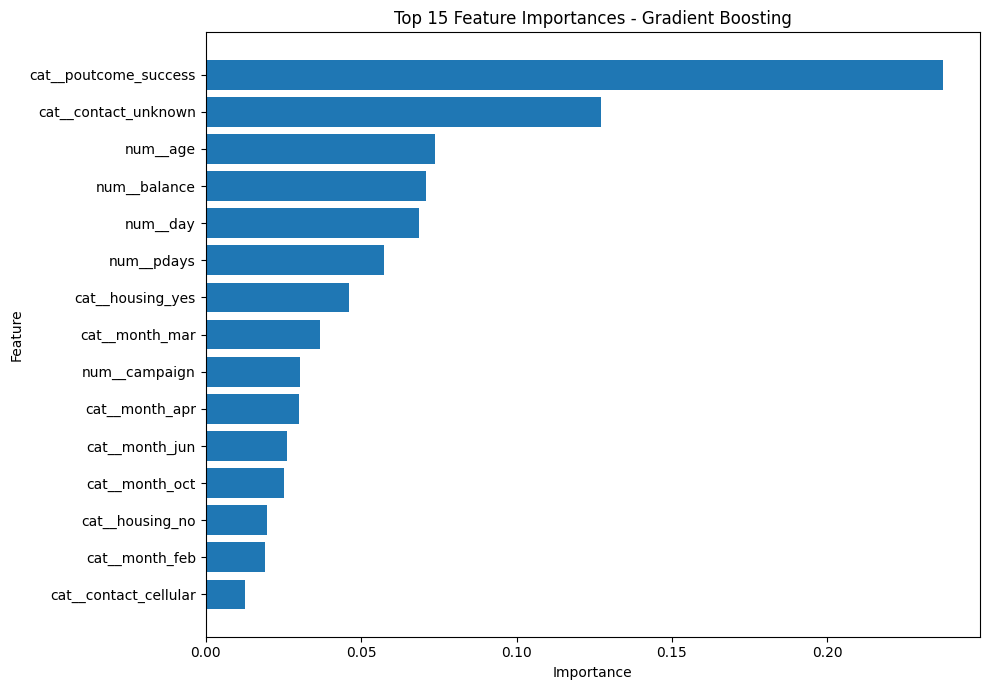

In [23]:
import matplotlib.pyplot as plt

top_features = importance_df.head(15).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 7))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 15 Feature Importances - Gradient Boosting")
plt.tight_layout()
plt.show()

In [24]:
# Checking whether the model is overfitting or underfitting

# Training accuracy
train_accuracy = best_model.score(X_train, y_train)

# Testing accuracy
test_accuracy = best_model.score(X_test, y_test)

print("Training Accuracy:", train_accuracy)
print("Testing Accuracy:", test_accuracy)

Training Accuracy: 0.7589875685967074
Testing Accuracy: 0.7451858486341245


ROC-AUC Score: 0.7945690383300487


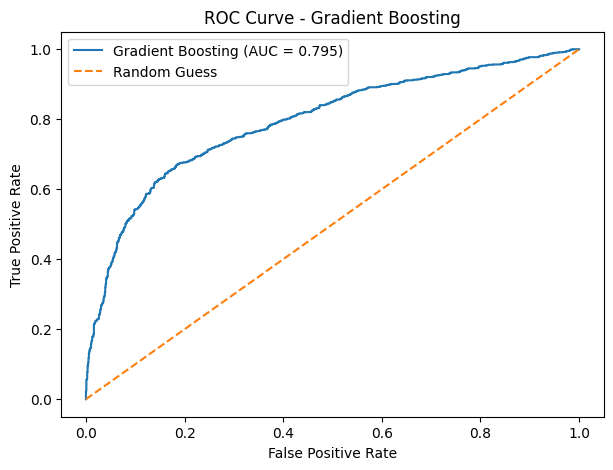

In [25]:
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt

# Get probability of the "yes" class
y_prob = best_model.predict_proba(X_test)[:, 1]

# Calculate ROC-AUC score
auc_score = roc_auc_score(y_test, y_prob)

print("ROC-AUC Score:", auc_score)

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(
    y_test, y_prob, pos_label="yes"
)

# Plot ROC curve
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Gradient Boosting (AUC = {auc_score:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random Guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Gradient Boosting")
plt.legend()
plt.show()